In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

ATTRIBUTIONS_PATH = "/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_rub_scores/attributions_full_wrongness_f0p2_max8t_output_metric2.csv"#attributions_validation_wrongness_metric2_output.csv"#"/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_rub_scores/attributions_full_wrongness_f0p2_max8t_output.csv"
HUMAN_SCORES_PATH = None #"/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_rub_scores/career_40_t_metric2/human_scores.csv"#"/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_rub_scores/career_40_t_metric1_v1/human_scores.csv"

attributions_df = pd.read_csv(ATTRIBUTIONS_PATH)

d = np.load("/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/scped_IFS/token_scores_olmo_career.npz")
df = pd.DataFrame({k: d[k] for k in d.files })

print(df.head(100))

print(attributions_df.head(100))


    example_idx  position  token_id        score
0             0        74      1271  -671.944580
1             0        75      3480   592.391663
2             0        76       505  -129.717651
3             0        77     33400  -240.599060
4             0        78       311     7.384064
..          ...       ...       ...          ...
95            1        86     21760 -1208.204712
96            1        87       389  -309.688965
97            1        88     46305 -1913.007324
98            1        89      5151   191.992950
99            1        90      1093    26.494476

[100 rows x 4 columns]
    example_idx  position  token_id    token_text     metric     score
0             0       142      3629         often  wrongness  5.194281
1             0        80     15009   engineering  wrongness  4.208467
2             0        75      3480        switch  wrongness  0.338780
3             0       115     30554         skill  wrongness  4.881258
4             0        99      65

In [32]:
if HUMAN_SCORES_PATH:
    human_df = pd.read_csv(HUMAN_SCORES_PATH)

    merged = pd.merge(
        attributions_df[["example_idx", "position", "token_text", "score"]],
        human_df[["example_idx", "position", "human_score"]],
        on=["example_idx", "position"],
    ).sort_values(["example_idx", "position"]).reset_index(drop=True)

    print(merged)

In [33]:

if HUMAN_SCORES_PATH:

    x = range(len(merged))
    diff = merged["score"] - merged["human_score"]
    print("mean diff = ", diff.mean())
    print("abs mean diff = ", diff.abs().mean())

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[2, 1])

    ax1.plot(x, merged["score"], marker="o", label="LLM judge")
    ax1.plot(x, merged["human_score"], marker="o", label="Human")
    ax1.set_ylabel("score")
    ax1.legend()

    ax2.axhline(0, color="gray", linewidth=0.8)
    ax2.plot(x, diff, marker="o", color="tab:red")
    ax2.set_ylabel("diff (llm - human)")
    ax2.set_xlabel("token index")

    plt.tight_layout()
    plt.show()

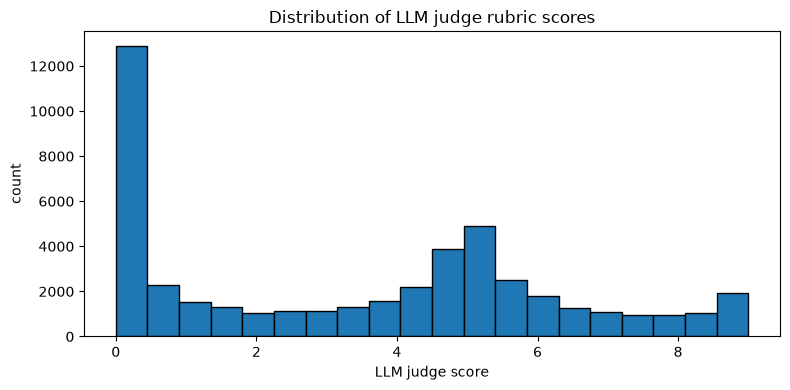

In [34]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(attributions_df["score"].dropna(), bins=20, edgecolor="black")
ax.set_xlabel("LLM judge score")
ax.set_ylabel("count")
ax.set_title("Distribution of LLM judge rubric scores")
plt.tight_layout()
plt.show()

In [37]:
if HUMAN_SCORES_PATH:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(merged["human_score"].dropna(), bins=20, edgecolor="black")
    ax.set_xlabel("Human score")
    ax.set_ylabel("count")
    ax.set_title("Distribution of LLM judge rubric scores")
    plt.tight_layout()
    plt.show()

In [ ]:
from scipy.stats import spearmanr

df_merged = df.merge(attributions_df, on=["example_idx", "position", "token_id"], suffixes=["_IF", "_rubric"])
print(f"{len(df_merged)}/{len(attributions_df)} rubric-scored tokens matched an IF score")

corr, pval = spearmanr(df_merged["score_IF"], df_merged["score_rubric"])
print(f"Spearman r={corr:.3f}, p={pval:.2e}")
print(df_merged.head(100))

plt.scatter(df_merged["score_IF"], df_merged["score_rubric"], s=4, alpha=0.2, rasterized=True)
plt.xlabel("IF score")
plt.ylabel("rubric score (wrongness)")
plt.text(0.05, 0.95, f"Spearman r={corr:.3f}\np={pval:.2e}",
         transform=plt.gca().transAxes, va="top",
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
plt.show()

In [ ]:
from scipy.stats import mannwhitneyu


def auroc_top_x(df, x_pct, score_col="score_rubric", if_col="score_IF"):
    """AUROC for score_col as a predictor of 'is this token in the top x_pct% by if_col'.
    Computed via Mann-Whitney U (AUROC = U / (n_pos * n_neg)) to avoid needing sklearn."""
    threshold = df[if_col].quantile(1 - x_pct / 100)
    is_top = (df[if_col] >= threshold).to_numpy()
    pos = df.loc[is_top, score_col].to_numpy()
    neg = df.loc[~is_top, score_col].to_numpy()
    U, _ = mannwhitneyu(pos, neg, alternative="two-sided")
    return U / (len(pos) * len(neg))


x_values = [1, 2, 5, 10, 20, 30, 40, 50]
aurocs = [auroc_top_x(df_merged, x) for x in x_values]

for x, a in zip(x_values, aurocs):
    print(f"top {x:>2}% most influential: AUROC = {a:.3f}")

plt.plot(x_values, aurocs, marker="o")
plt.axhline(0.5, color="gray", linestyle="--", label="chance")
plt.xlabel("top X% most influential tokens (by IF score)")
plt.ylabel("AUROC (wrongness score as predictor)")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
def roc_curve_manual(is_top, scores):
    order = np.argsort(-scores)
    y_sorted = is_top[order]
    tps = np.cumsum(y_sorted)
    fps = np.cumsum(~y_sorted)
    tpr = tps / tps[-1]
    fpr = fps / fps[-1]
    return np.concatenate([[0], fpr]), np.concatenate([[0], tpr])


plt.figure(figsize=(6, 6))
for x in [5, 10, 20, 50]:
    threshold = df_merged["score_IF"].quantile(1 - x / 100)
    is_top = (df_merged["score_IF"] >= threshold).to_numpy()
    fpr, tpr = roc_curve_manual(is_top, df_merged["score_rubric"].to_numpy())
    plt.plot(fpr, tpr, label=f"top {x}% (AUROC={auroc_top_x(df_merged, x):.3f})")

plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="chance")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC: wrongness score predicting 'is this token in the top X% most influential'")
plt.legend()
plt.tight_layout()
plt.show()
